# Disease-alert model

This notebook trains a gradient boosting model to answer the question of whether a particular group of the farm's animals are likely to encounter a particular disease in the next 30 days.

## 1. Installing dependencies and importing libraries

Inside Docker every library in `requirements.txt` is already installed. On another computer, remove the `#` from the next line and run it once.

In [1]:
import sys
import time
import warnings
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_auc_score)

## 2. Setting up the environment

- **Where the project is.** The notebook lives in `notebooks/`, and the project's code is in the ml folder. Adding that folder to `sys.path` lets us `import ml`.
- **One random seed** (inside `ml/disease_model.py`), so every run gives the same farms and the same numbers.
- **Display settings** for tables and charts.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
OLIVE, TAN, GREY = "#5a6b3a", "#b08d57", "#9a9a9a"

# The project's own code: the same steps the app uses.
from ml.reference import CONDITIONS, LONG_RAINS, SHORT_RAINS, predicted_conditions
from ml.groups import GROUPS, pairs
from ml.disease_data import CATEGORIES, FEATURES, LABEL, NUMBERS, build_table
from ml.disease_model import (END, FARMS, MODEL_PATH, SEED, TEST_FARMS, YEARS, SeasonalCalendar,
                              boosting, last_year_rule, load_bundle, logistic, save_bundle, split)
from ml.synthetic import simulate_many
from ml.farm_records import demo_farm, kwetu

print("Project folder:", ROOT)

Project folder: /app


## 3. The disease knowledge

The model predicts **common and seasonal** diseases that are easy to learn from then more rare diseases are turned into alerts and put on a watch list for the farmer.

Each disease in `ml/reference.py` carries its facts: who gets it, what raises it, the advice for the farmer, and the source. The simulator raises the risk useing triggers. 

- `rains`: long rains (March to May) or short rains (October to December). 
- `rains_onset`: the first month of each rainy season (worms hatch in warm, wet weather).
- `el_nino`: an El Niño season. El Niño brings heavy short rains, October to January. 
- `spray_lapse`, `deworm_overdue`, `vaccine_overdue`: the farm's routines slipping.
- `contagious`: each recent case raises the herd's risk.
- `environment`: the farm's surroundings (wet ground, ticks, hygiene). This is why a farm that had a lot of a disease last year tends to have it again.

In [3]:
rows = []
for species in CONDITIONS:
    for c in predicted_conditions(species):
        rows.append({"species": species.title(), "disease": c.name, "how common": c.rank,
                     "raised by": ", ".join(c.triggers) or "-", "surroundings": c.environment or "-",
                     "source": c.source or "Kwetu's records"})
knowledge = pd.DataFrame(rows)
print(f"{len(knowledge)} species-disease pairs the model predicts")
knowledge

41 species-disease pairs the model predicts


,species,disease,how common,raised by,surroundings,source
0,Cattle,East Coast Fever,common,"rains, spray_lapse",ticks,UoN Faculty of Veterinary Medicine lecture not...
1,Cattle,Calf scours,common,contagious,hygiene,UoN Faculty of Veterinary Medicine lecture not...
2,Cattle,Coccidiosis,occasional,"rains, contagious",hygiene,UoN Faculty of Veterinary Medicine lecture not...
3,Cattle,Gastrointestinal worms,common,"rains, rains_onset, deworm_overdue",wet,UoN Faculty of Veterinary Medicine lecture not...
4,Cattle,Liver fluke,occasional,rains,wet,UoN Faculty of Veterinary Medicine lecture not...
5,Cattle,Mastitis,common,rains,hygiene,Merck Veterinary Manual: Mastitis in large ani...
6,Cattle,Foot rot,occasional,"rains, el_nino",wet,UoN Faculty of Veterinary Medicine lecture not...
7,Cattle,Laminitis,occasional,el_nino,-,UoN Faculty of Veterinary Medicine lecture not...
8,Cattle,Blackquarter,occasional,"rains, vaccine_overdue",-,UoN Faculty of Veterinary Medicine lecture not...
9,Cattle,Lumpy skin disease,occasional,"rains, el_nino, vaccine_overdue",-,UoN Faculty of Veterinary Medicine lecture not...


## 4. The animal groups

Each species is split into groups that share the same risks (`ml/groups.py`). An animal's group depends on its age and on whether it gave birth in the last 60 days. A disease is only predicted for the groups that can get it: calf scours only in calves, mastitis only in grown females, laminitis only in cows after calving.

In [4]:
group_list = pd.DataFrame(pairs(), columns=["species", "group", "disease"])
group_list.groupby(["species", "group"], sort=False)["disease"].agg(
    diseases="size", examples=lambda d: ", ".join(list(d)[:4]) + ("..." if len(d) > 4 else ""))

diseases                                           examples
species group                                                                          
CATTLE  Calves                     7  East Coast Fever, Calf scours, Coccidiosis, Ga...
        Young stock                7  East Coast Fever, Coccidiosis, Gastrointestina...
        Cows after calving         8  East Coast Fever, Gastrointestinal worms, Live...
        Adult cattle               6  East Coast Fever, Gastrointestinal worms, Live...
GOAT    Kids                      10  Pneumonia, Lungworm, Gastrointestinal worms, C...
        Does after kidding         9  Pneumonia, Lungworm, Gastrointestinal worms, V...
        Adult goats                9  Pneumonia, Lungworm, Gastrointestinal worms, V...
SHEEP   Lambs                     11  Pneumonia, Lungworm, Gastrointestinal worms, L...
        Ewes after lambing         9  Pneumonia, Lungworm, Gastrointestinal worms, L...
        Adult sheep                9  Pneumonia, Lungworm, Gastrointestinal worms, L...
CHICKEN Flock                      8  Coccidiosis, Bacterial respiratory disease, Ga...

## 5. Loading the data

### a. Ten simulated farms

`simulate_many` runs the farm simulator ten times. Each farm gets:
- its own **vaccination plan** (Kwetu's, every vaccine, or almost none);
- its own **surroundings**: `wet`, `ticks` and `hygiene`, drawn around 1.0 (average). For example, 2.0 means twice the usual risk of the diseases that factor drives.

Four years are simulated. The first year only builds up history, so that every example has a full year behind it.

In [5]:
started = time.time()
tables, farms = simulate_many(FARMS, END, YEARS, SEED)
print(f"Simulated {FARMS} farms in {time.time() - started:.0f} seconds")
pd.Series({name: len(df) for name, df in tables.items()}, name="rows").to_frame().T

Simulated 10 farms in 255 seconds


,livestock,breeding,mortality,commercial,health,herd_activities,weights,el_nino
rows,9378,4504,1201,1437,215876,7609,36034,20


In [6]:
farms

,vaccination plan,wet,ticks,hygiene
farm,,,,
farm01,full,0.42,0.99,1.33
farm02,full,0.52,0.25,1.20
farm03,kwetu,1.22,3.06,1.48
farm04,full,1.62,0.39,1.23
farm05,kwetu,1.17,1.17,0.57
farm06,full,0.80,1.77,2.75
farm07,kwetu,1.42,1.01,1.12
farm08,kwetu,1.05,0.27,0.81
farm09,kwetu,4.83,0.86,2.80


### b. The demo farm and Kwetu records

`ml/farm_records.py` reads each Excel workbook into the same tables the simulator makes, so the same code can build their examples.

Kwetu writes illnesses in its own words. Only those that match a disease the model predicts are kept.

In [7]:
demo = demo_farm()
real = kwetu()
for name, data in (("Demo farm", demo), ("Kwetu", real)):
    h = data["health"]
    ill = h[h["record_type"] == "ILLNESS"]
    print(f"{name}: {len(data['livestock'])} animals, {ill['disease'].notna().sum()} illnesses the model covers, "
          f"{h['date'].min():%d/%m/%Y} to {h['date'].max():%d/%m/%Y}")

Demo farm: 649 animals, 639 illnesses the model covers, 01/11/2024 to 31/10/2026
Kwetu: 574 animals, 42 illnesses the model covers, 25/03/2026 to 02/09/2026


## 6. Exploring the simulated farms

Before modelling, check that the data shows the patterns the model is meant to learn: seasons, groups, El Niño, and farms that differ from each other year after year.

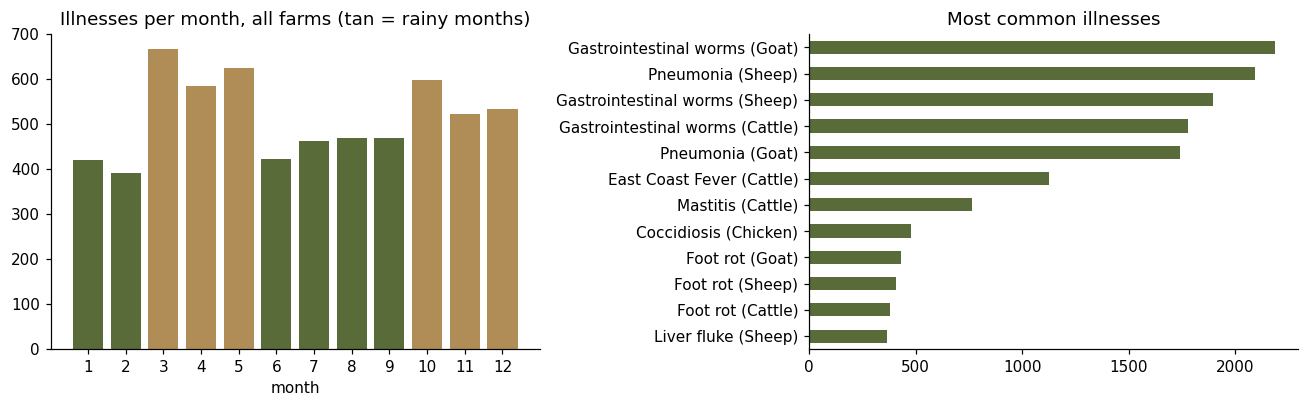

In [8]:
health = tables["health"].merge(tables["livestock"][["animal_id", "species"]], on="animal_id")
ill = health[health["record_type"] == "ILLNESS"].copy()
ill["date"] = pd.to_datetime(ill["date"])
ill = ill[ill["date"] >= pd.Timestamp(END - timedelta(days=365 * (YEARS - 1)))]   # after the first year

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
by_month = ill.groupby(ill["date"].dt.month).size() / (YEARS - 1)
colours = [TAN if m in LONG_RAINS + SHORT_RAINS else OLIVE for m in by_month.index]
axes[0].bar(by_month.index, by_month.values, color=colours)
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Illnesses per month, all farms (tan = rainy months)")
axes[0].set_xlabel("month")
top = ill.groupby(["species", "disease"]).size().sort_values().tail(12)
top.index = [f"{d} ({s.title()})" for s, d in top.index]
top.plot.barh(ax=axes[1], color=OLIVE, title="Most common illnesses")
plt.tight_layout()

Illness rises in the rainy months (March to May, October to December), which is the seasonal pattern the alerts need to catch.

In [9]:
def share_in_rains(disease):
    d = ill[ill["disease"] == disease]
    return d["date"].dt.month.isin(LONG_RAINS + SHORT_RAINS).mean()

seasonal = pd.Series({d: share_in_rains(d) for d in ["Gastrointestinal worms", "East Coast Fever", "Foot rot",
                                                     "Coccidiosis", "Mastitis", "Orf", "Mange"]})
print("Share of cases in the rainy months (half the year is rainy, so 0.50 = no season):")
seasonal.round(2).sort_values(ascending=False)

Share of cases in the rainy months (half the year is rainy, so 0.50 = no season):


Gastrointestinal worms    0.60
Foot rot                  0.60
Coccidiosis               0.59
East Coast Fever          0.57
Mastitis                  0.55
Mange                     0.49
Orf                       0.48
dtype: float64

**El Niño.** Each farm's El Niño seasons are in `tables["el_nino"]`. In an El Niño season, foot rot, laminitis and lumpy skin disease should be much higher than in a normal October to January. The table shows the average cases per farm in one October-to-January season.

In [10]:
nino_months = ill[ill["date"].dt.month.isin([10, 11, 12, 1])].copy()
nino_months["season"] = np.where(nino_months["date"].dt.month == 1, nino_months["date"].dt.year - 1,
                                 nino_months["date"].dt.year)
el_nino_years = set(zip(tables["el_nino"]["farm"], pd.to_datetime(tables["el_nino"]["start"]).dt.year))
farm_seasons = pd.MultiIndex.from_product([sorted(ill["farm"].unique()), range(2022, 2026)],
                                          names=["farm", "season"])
rows = {}
for disease in ["Foot rot", "Laminitis", "Lumpy skin disease"]:
    counts = (nino_months[nino_months["disease"] == disease].groupby(["farm", "season"]).size()
              .reindex(farm_seasons, fill_value=0))
    is_nino = [key in el_nino_years for key in counts.index]
    rows[disease] = {"El Niño season": counts[is_nino].mean(),
                     "Normal season": counts[[not x for x in is_nino]].mean()}
print(f"{len(el_nino_years)} farm-seasons with El Niño, out of {len(farm_seasons)}")
pd.DataFrame(rows).T.round(2)

20 farm-seasons with El Niño, out of 40


,El Niño season,Normal season
Foot rot,21.53,7.64
Laminitis,1.00,0.20
Lumpy skin disease,0.67,0.08


**Farms differ, and the difference lasts.** If a farm had a lot of a disease last year, does it have a lot again this year? That is what makes the farm's own history useful. The chart compares each farm's cases per 100 animals in the second and third simulated years, for a few diseases.

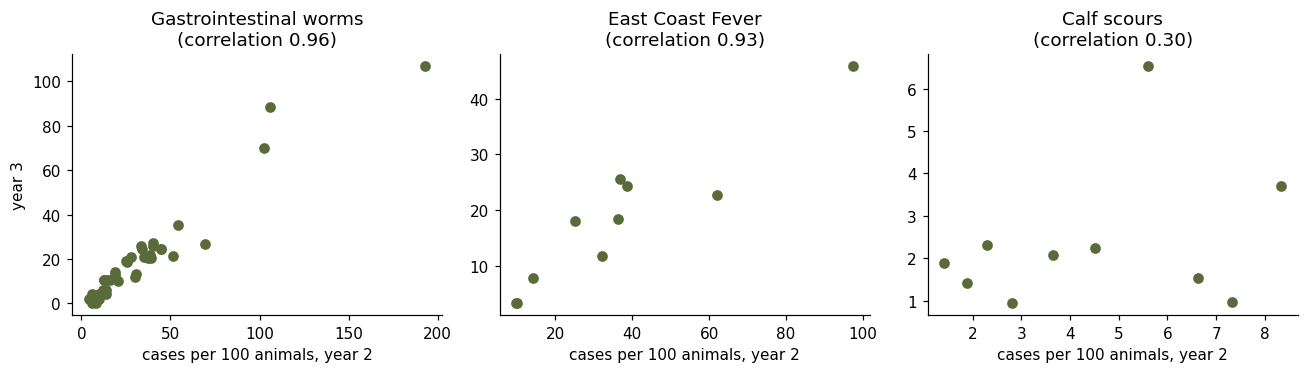

In [11]:
herd = tables["livestock"].groupby(["farm", "species"]).size()
ill["year"] = np.where(ill["date"] < pd.Timestamp("2025-10-01"), "year 2", "year 3")
yearly = ill.groupby(["farm", "species", "disease", "year"]).size().unstack(fill_value=0)
yearly = yearly.div(herd.reindex(yearly.index.droplevel("disease")).to_numpy(), axis=0) * 100

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, disease in zip(axes, ["Gastrointestinal worms", "East Coast Fever", "Calf scours"]):
    d = yearly.xs(disease, level="disease")
    ax.scatter(d["year 2"], d["year 3"], color=OLIVE)
    ax.set_title(f"{disease}\n(correlation {d['year 2'].corr(d['year 3']):.2f})")
    ax.set_xlabel("cases per 100 animals, year 2")
axes[0].set_ylabel("year 3")
plt.tight_layout()

## 7. Building the examples

`build_table` (in `ml/disease_data.py`) takes a snapshot every 14 days. For each farm, each group that has animals that day, and each disease that group can get, it writes one row.

**The answer (label):** `disease_within_30_days` is 1 if the disease appeared in that group within the next 30 days.

**The clues (features)** use only records on or before the snapshot day (what the farmer could know):

| Clue | Meaning |
|---|---|
| species, group, disease | which pair we are asking about |
| season, month | the season and month in the middle of the next 30 days |
| rains_start_soon | 1 if the rains begin within the next 30 days |
| el_nino | 1 in an El Niño season. In the app it comes from the farmer's switch ("El Niño is forecast"), and only counts from October to January |
| group_size | how many animals are in the group |
| cases_last_30_days | cases of this disease in this species on the farm, last 30 days |
| cases_last_year | the same, last 365 days |
| cases_this_time_last_year | the same, in the same 30 days a year ago |
| days_since_deworming, days_since_spraying | the herd's routines |
| longest_spray_gap | the longest stretch with no tick spraying in the last 21 days. `days_since_spraying` forgets a missed week as soon as spraying restarts, but the ticks it let through cause East Coast Fever and heartwater 1 to 3 weeks later. Normal is 3-4 days for cattle and 7 for goats and sheep; a missed week makes it about 11 or 14 |
| vaccine_coverage, has_vaccine | the share of the group whose vaccine against this disease is in date |

For common diseases (worms, East Coast Fever) a farm's level is almost the same from one year to the next: muddy or tick-infested farms stay that way. For calf scours there are only a few cases per farm, so chance dominates and the correlation is weak.

In [12]:
start = END - timedelta(days=365 * (YEARS - 1))
table = build_table(tables, start, END)
print(f"{len(table):,} rows, {table['snapshot'].nunique()} snapshot days, "
      f"{table[LABEL].mean():.1%} of rows had the disease within 30 days")
table.sample(5, random_state=SEED)

71,364 rows, 77 snapshot days, 25.1% of rows had the disease within 30 days


,farm,snapshot,species,group,group_size,disease,season,month,el_nino,rains_start_soon,cases_last_30_days,cases_last_year,cases_this_time_last_year,days_since_deworming,days_since_spraying,longest_spray_gap,has_vaccine,vaccine_coverage,disease_within_30_days
60654,farm05,2026-03-29,GOAT,Kids,42,Pneumonia,long rains,4,0,0,10,89,5,7,4.0,14.0,0,0.000000,1
34273,farm01,2025-03-02,GOAT,Adult goats,125,Lungworm,long rains,3,0,0,2,10,1,87,4.0,7.0,0,0.000000,1
587,farm07,2023-10-01,GOAT,Adult goats,98,Lungworm,short rains,10,1,0,0,6,0,76,4.0,7.0,0,0.000000,0
24901,farm10,2024-09-29,CHICKEN,Flock,46,Newcastle disease,short rains,10,0,1,0,6,0,6,365.0,365.0,1,0.000000,0
47716,farm06,2025-09-14,CATTLE,Young stock,22,Lumpy skin disease,dry,9,0,1,0,2,0,94,10.0,11.0,1,0.909091,0


How often each disease appears differs a lot between groups. Pneumonia in a big flock of adult sheep is nearly certain within a month, while blackquarter in young stock is rare. The model has to know these base rates, and then do better than them.

In [13]:
table.groupby(["species", "group", "disease"])[LABEL].mean().unstack("group").round(2).fillna("")

/tmp/ipykernel_47/2421524217.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  table.groupby(["species", "group", "disease"])[LABEL].mean().unstack("group").round(2).fillna("")


group                                 Adult cattle Adult goats Adult sheep Calves Cows after calving Does after kidding  \
species disease                                                                                                           
CATTLE  Blackquarter                                                                                                      
        Calf scours                                                          0.15                                         
        Coccidiosis                                                          0.05                                         
        East Coast Fever                      0.76                           0.16               0.05                      
        Foot rot                              0.44                           0.05               0.02                      
        Gastrointestinal worms                0.85                           0.39               0.12                      
        Laminitis                                                                               0.08                      
        Liver fluke                           0.41                           0.03               0.02                      
        Lumpy skin disease                    0.05                            0.0                0.0                      
        Mastitis                              0.77                                              0.17                      
        Retained afterbirth                                                                      0.0                      
CHICKEN Bacterial enteritis                                                                                               
        Bacterial respiratory disease                                                                                     
        Coccidiosis                                                                                                       
        External parasites                                                                                                
        Footpad dermatitis                                                                                                
        Fowl pox                                                                                                          
        Gastrointestinal worms                                                                                            
        Newcastle disease                                                                                                 
GOAT    Coccidiosis                                                                                                       
        Dermatophilosis                                   0.46                                                     0.05   
        Diarrhoea                                                                                                         
        Foot rot                                          0.53                                                     0.05   
        Gastrointestinal worms                            0.92                                                     0.19   
        Lungworm                                          0.41                                                     0.04   
        Mange                                             0.42                                                     0.04   
        Mastitis                                          0.32                                                     0.11   
        Orf                                               0.23                                                     0.02   
        Pneumonia                                         0.92                                                     0.19   
        Vulval infection                                  0.32                                                     0.04   
SHEEP   Bluetongue                                              

## 8. Splitting the data

There are three parts:
- **learn:** the older 75% of snapshot days, on eight farms.
- **test (same farms, later):** the newest 25% on the same eight farms. Does it predict the future?
- **test (new farms):** the newest 25% on the two farms it **never saw**. Does it work on a farm it hasn't learnt from? This is the situation of a new farmer joining the app.

The split is by time, as in the earlier model. A random split would let it learn from days after the ones it is tested on, and it would see the same farm, group and disease a fortnight apart on both sides (leakage).

In [14]:
learn, test_time, test_farms = split(table)
pd.DataFrame({"rows": [len(learn), len(test_time), len(test_farms)],
              "farms": [learn["farm"].nunique(), test_time["farm"].nunique(), test_farms["farm"].nunique()],
              "from": [learn["snapshot"].min(), test_time["snapshot"].min(), test_farms["snapshot"].min()],
              "to": [learn["snapshot"].max(), test_time["snapshot"].max(), test_farms["snapshot"].max()],
              "share with disease": [learn[LABEL].mean(), test_time[LABEL].mean(), test_farms[LABEL].mean()]},
             index=["learn", "test: same farms, later", "test: new farms"]).round(3)

/tmp/ipykernel_47/3738999729.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  index=["learn", "test: same farms, later", "test: new farms"]).round(3)


,rows,farms,from,to,share with disease
learn,42242,8,2023-10-01,2025-11-23,0.233
"test: same farms, later",14840,8,2025-12-07,2026-08-30,0.256
test: new farms,3720,2,2025-12-07,2026-08-30,0.320


## 9. The rules the model must beat

A model is only worth having if it does better than simple rules a farmer or a spreadsheet could follow. There are two such rules:

1. **"Same as last year":** expect what happened at this time last year (`cases_this_time_last_year`).
2. **A seasonal calendar:** for each species, group, disease and month, the share of training rows that had a case. This is a lookup table, not ML, and it already knows which diseases are common in which groups and seasons.

If the model can't beat the calendar, an ML model isn't needed.

In [15]:
calendar = SeasonalCalendar().fit(learn)

## 10. Choosing the model

Three models are compared, all trained on `learn` and checked with **time-ordered cross-validation**: each fold trains on earlier snapshot days and validates on later ones.

- **Logistic regression:** one weight per clue, as in the earlier model.
- **Random forest:** many deep trees, averaged.
- **Gradient boosting:** many small trees, each correcting the last.

Trees can learn **combinations**, for example worms × rains × young animals, without being told. Logistic regression can only add effects up.

In [16]:
def time_folds(rows, n=4):
    """Split by snapshot day: fold k trains on the days before block k and validates on block k."""
    days = np.array(sorted(rows["snapshot"].unique()))
    blocks = np.array_split(days, n + 1)
    for k in range(1, n + 1):
        yield (rows.index[rows["snapshot"] < blocks[k][0]],
               rows.index[rows["snapshot"].isin(blocks[k])])


def forest():
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OrdinalEncoder
    prepare = ColumnTransformer([("categories", OrdinalEncoder(), CATEGORIES), ("numbers", "passthrough", NUMBERS)])
    return Pipeline([("prepare", prepare), ("model", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=40, n_jobs=-1, random_state=SEED))])


learn = learn.reset_index(drop=True)
results = []
for name, make in (("Logistic regression", logistic), ("Random forest", forest), ("Gradient boosting", boosting)):
    began, scores = time.time(), []
    for train_idx, valid_idx in time_folds(learn):
        fitted = make().fit(learn.loc[train_idx, FEATURES], learn.loc[train_idx, LABEL])
        p = fitted.predict_proba(learn.loc[valid_idx, FEATURES])[:, 1]
        scores.append(roc_auc_score(learn.loc[valid_idx, LABEL], p))
    results.append({"model": name, "CV ROC AUC": np.mean(scores), "spread": np.std(scores),
                    "seconds": time.time() - began})
pd.DataFrame(results).set_index("model").round(3)

,CV ROC AUC,spread,seconds
model,,,
Logistic regression,0.849,0.007,3.389
Random forest,0.854,0.006,7.346
Gradient boosting,0.857,0.008,4.807


### Tuning gradient boosting

A small grid of settings: how fast it learns (`learning_rate`) and how big each tree can grow (`max_leaf_nodes`). The same time-ordered folds are used.

In [17]:
grid = []
for rate in (0.03, 0.05, 0.1):
    for leaves in (15, 31):
        scores = []
        for train_idx, valid_idx in time_folds(learn):
            model = boosting().set_params(model__learning_rate=rate, model__max_leaf_nodes=leaves)
            model.fit(learn.loc[train_idx, FEATURES], learn.loc[train_idx, LABEL])
            scores.append(roc_auc_score(learn.loc[valid_idx, LABEL],
                                        model.predict_proba(learn.loc[valid_idx, FEATURES])[:, 1]))
        grid.append({"learning_rate": rate, "max_leaf_nodes": leaves, "CV ROC AUC": np.mean(scores)})
grid = pd.DataFrame(grid).sort_values("CV ROC AUC", ascending=False)
grid.round(4)

,learning_rate,max_leaf_nodes,CV ROC AUC
0,0.03,15,0.8575
2,0.05,15,0.8562
1,0.03,31,0.8543
3,0.05,31,0.8536
4,0.10,15,0.8532
5,0.10,31,0.8490


The three models were close in cross-validation (within about 0.005). Tuning lifts gradient boosting to the top: a slower learning rate (0.03) and smaller trees (15 leaves) score best. Those settings are now the defaults in `boosting()` in `ml/disease_model.py`.

**Decision: tuned gradient boosting.** It has the best cross-validated score after tuning, it handles the text columns (species, group, disease, season) directly, and its chances are well calibrated (section 13). Section 11 checks it on the test sets.

## 11. Testing: does the model beat the rules?

Four numbers for each approach:
- **ROC AUC:** how well it ranks rows that had the disease above rows that didn't (0.5 = guessing, 1 = perfect).
- **Average precision:** like ROC AUC, but focused on the "yes" rows.
- **Brier score:** the average squared gap between the predicted chance and what happened (lower is better). It checks that the chances are honest.
- **Within-pair ROC AUC:** the ROC AUC computed **separately for each species-group-disease pair**, then averaged. It asks the hardest question: for the same disease in the same group, does the model know **when** and **on which farm** it will strike? The overall ROC AUC is helped a lot by knowing that pneumonia is common and blackquarter rare, and the calendar knows that too.

In [18]:
def within_pair_auc(rows, chance, min_cases=5):
    scores = []
    for _, g in rows.assign(chance=chance).groupby(["species", "group", "disease"]):
        if g[LABEL].nunique() == 2 and g[LABEL].sum() >= min_cases:
            scores.append(roc_auc_score(g[LABEL], g["chance"]))
    return np.mean(scores) if scores else np.nan


model = boosting().fit(learn[FEATURES], learn[LABEL])
logit = logistic().fit(learn[FEATURES], learn[LABEL])


def compare(rows):
    y = rows[LABEL]
    approaches = {"Gradient boosting": model.predict_proba(rows[FEATURES])[:, 1],
                  "Logistic regression": logit.predict_proba(rows[FEATURES])[:, 1],
                  "Seasonal calendar (no ML)": calendar.predict(rows),
                  "Same as last year (no ML)": last_year_rule(rows).to_numpy()}
    out = []
    for name, chance in approaches.items():
        is_chance = not name.startswith("Same")
        out.append({"approach": name, "ROC AUC": roc_auc_score(y, chance),
                    "average precision": average_precision_score(y, chance),
                    "Brier": brier_score_loss(y, chance) if is_chance else np.nan,
                    "within-pair ROC AUC": within_pair_auc(rows, chance)})
    return pd.DataFrame(out).set_index("approach").round(3)


print("Same farms, later months")
display(compare(test_time))
print("Farms the model never saw")
display(compare(test_farms))

Same farms, later months


,ROC AUC,average precision,Brier,within-pair ROC AUC
approach,,,,
Gradient boosting,0.873,0.734,0.118,0.631
Logistic regression,0.860,0.712,0.125,0.594
Seasonal calendar (no ML),0.843,0.679,0.130,0.528
Same as last year (no ML),0.723,0.465,NaN,0.577


Farms the model never saw


,ROC AUC,average precision,Brier,within-pair ROC AUC
approach,,,,
Gradient boosting,0.862,0.781,0.133,0.623
Logistic regression,0.854,0.749,0.140,0.589
Seasonal calendar (no ML),0.819,0.710,0.161,0.511
Same as last year (no ML),0.723,0.572,NaN,0.554


**Reading the results:**
- The model ranks better than both rules on both test sets, including farms it never saw.
- The calendar's within-pair score is close to 0.5. Knowing the month alone says little about *whether this group on this farm* will be hit. The model's within-pair score is clearly higher, because it also uses the farm's own history, recent cases, routines and vaccine coverage.
- "Same as last year" helps, but less than the model, which combines it with everything else.
- The model's Brier score is the lowest, so its chances are the most honest.

## 12. Results per disease

Which diseases does the model predict well? Within-pair ROC AUC per disease (on both test sets together), next to the calendar.

In [19]:
both = pd.concat([test_time, test_farms])
both = both.assign(model=model.predict_proba(both[FEATURES])[:, 1], calendar=calendar.predict(both))
per = []
for (species, disease), g in both.groupby(["species", "disease"]):
    if g[LABEL].nunique() == 2 and g[LABEL].sum() >= 10:
        per.append({"species": species.title(), "disease": disease, "rows": len(g), "share with disease": g[LABEL].mean(),
                    "model": roc_auc_score(g[LABEL], g["model"]), "calendar": roc_auc_score(g[LABEL], g["calendar"])})
per = pd.DataFrame(per).sort_values("model", ascending=False).round(3)
per

,species,disease,rows,share with disease,model,calendar
22,Goat,Gastrointestinal worms,600,0.667,0.893,0.861
38,Sheep,Orf,600,0.175,0.889,0.717
33,Sheep,Foot rot,600,0.225,0.888,0.856
3,Cattle,East Coast Fever,795,0.335,0.885,0.842
34,Sheep,Gastrointestinal worms,600,0.580,0.885,0.866
27,Goat,Pneumonia,600,0.623,0.878,0.868
19,Goat,Dermatophilosis,600,0.263,0.871,0.839
4,Cattle,Foot rot,795,0.177,0.866,0.822
35,Sheep,Liver fluke,600,0.212,0.859,0.772
39,Sheep,Pneumonia,600,0.615,0.852,0.841


## 13. Are the chances honest? (calibration)

The app shows each chance to the farmer, so the chances must mean what they say. Rows are grouped by predicted chance, and each group's predicted chance is compared with how often the disease really appeared. On a well-calibrated model the points lie on the diagonal.

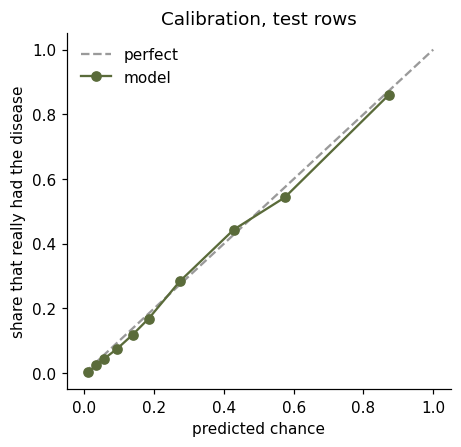

In [20]:
chance = model.predict_proba(test_time[FEATURES])[:, 1]
real_share, predicted = calibration_curve(test_time[LABEL], chance, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.plot([0, 1], [0, 1], "--", color=GREY, label="perfect")
ax.plot(predicted, real_share, "o-", color=OLIVE, label="model")
ax.set_xlabel("predicted chance")
ax.set_ylabel("share that really had the disease")
ax.legend(frameon=False)
ax.set_title("Calibration, test rows");

## 14. Alert levels and the confusion matrix

The alerts page sorts each group's diseases into three levels, by the chance of **at least one case in the group within 30 days**:

- **High:** 50% or more. Act now.
- **Watch:** 20% to 50%. Keep an eye out.
- **Low:** under 20%.

The confusion matrix treats "High" as a yes: how many High alerts were followed by the disease (precision), and how many cases had a High alert first (recall).

Precision: 70.4% of High alerts were followed by the disease (base rate 25.6%)
Recall:    54.6% of cases had a High alert first


,rows,share_with_disease
level,,
Low,8652,0.069
Watch,3239,0.348
High,2949,0.704


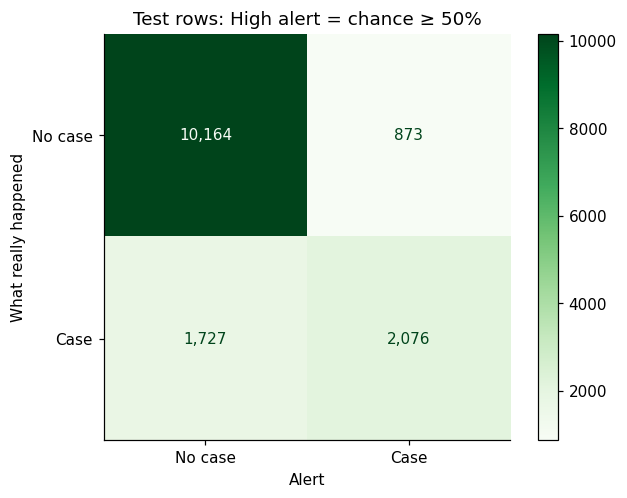

In [21]:
HIGH_FROM, WATCH_FROM = 0.50, 0.20
flagged = (chance >= HIGH_FROM).astype(int)
matrix = confusion_matrix(test_time[LABEL], flagged)
ConfusionMatrixDisplay(matrix, display_labels=["No case", "Case"]).plot(cmap="Greens", values_format=",")
plt.title(f"Test rows: High alert = chance ≥ {HIGH_FROM:.0%}")
plt.xlabel("Alert")
plt.ylabel("What really happened")
tn, fp, fn, tp = matrix.ravel()
print(f"Precision: {tp / (tp + fp):.1%} of High alerts were followed by the disease (base rate {test_time[LABEL].mean():.1%})")
print(f"Recall:    {tp / (tp + fn):.1%} of cases had a High alert first")
levels = pd.cut(chance, [0, WATCH_FROM, HIGH_FROM, 1], labels=["Low", "Watch", "High"], include_lowest=True)
test_time.assign(level=levels).groupby("level", observed=True)[LABEL].agg(rows="size", share_with_disease="mean").round(3)

## 15. What the model relies on

**Permutation importance:** shuffle one clue at a time on the test rows and see how much ROC AUC drops. A big drop means the model relies on that clue.

In [22]:
sample = test_time.sample(min(6000, len(test_time)), random_state=SEED)
importance = permutation_importance(model, sample[FEATURES], sample[LABEL], scoring="roc_auc",
                                    n_repeats=3, random_state=SEED)
pd.Series(importance.importances_mean, index=FEATURES, name="drop in ROC AUC").sort_values(ascending=False).round(4)

group_size                   0.1168
cases_last_year              0.0873
disease                      0.0259
group                        0.0181
vaccine_coverage             0.0143
season                       0.0038
cases_last_30_days           0.0006
cases_this_time_last_year    0.0006
month                        0.0001
days_since_deworming         0.0001
el_nino                      0.0000
species                      0.0000
rains_start_soon             0.0000
has_vaccine                  0.0000
days_since_spraying         -0.0000
longest_spray_gap           -0.0001
Name: drop in ROC AUC, dtype: float64

**Reading it:** the model relies most on **group size** (a big group is more likely to have at least one case) and on **the farm's own history** (`cases_last_year`), then on which disease and group it is and the vaccine coverage. The season adds a little: in the simulator the rains raise risk by 30-50%, a real but modest effect. El Niño and the spraying clues add almost nothing on their own; the next check shows why.

**The model's seasonal calendar.** For worms in the young and in older groups, here is the model's average predicted chance by month, over the test rows (December to August). The model learnt from the data, without being told, that risk rises through the long rains and that the young are at higher risk.

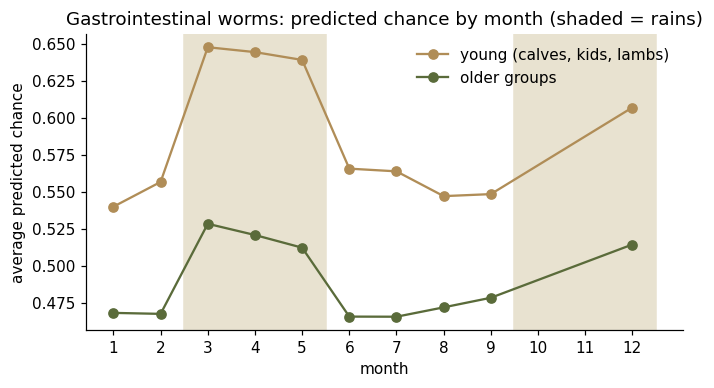

In [23]:
show = both[both["disease"] == "Gastrointestinal worms"]
young = show["group"].isin(["Calves", "Kids", "Lambs"])
fig, ax = plt.subplots(figsize=(7, 3.5))
for mask, label, colour in ((young, "young (calves, kids, lambs)", TAN), (~young, "older groups", OLIVE)):
    show[mask].groupby("month")["model"].mean().plot(ax=ax, marker="o", color=colour, label=label)
for m in LONG_RAINS + SHORT_RAINS:
    ax.axvspan(m - 0.5, m + 0.5, color="#e8e2d0", zorder=0)
ax.set_xticks(range(1, 13))
ax.set_ylabel("average predicted chance")
ax.set_title("Gastrointestinal worms: predicted chance by month (shaded = rains)")
ax.legend(frameon=False);

**Do the routine clues work?** Two checks on the test rows, changing one clue and keeping everything else the same:

1. **A missed spray week.** East Coast Fever and heartwater rows, with a normal spraying gap against a gap of 11 days (cattle) or 14 days (goats and sheep).
2. **The El Niño switch.** El Niño diseases from October to January, with `el_nino` off and on. The last column is what the data itself shows (the rate in El Niño seasons divided by the rate in normal ones).

In [24]:
tick_borne = ["East Coast Fever", "Leg paralysis (suspected heartwater)"]
rows = test_time[test_time["disease"].isin(tick_borne)]
normal_gap = np.where(rows["species"] == "CATTLE", 4, 7)
missed_gap = np.where(rows["species"] == "CATTLE", 11, 14)
spray_check = pd.DataFrame({
    "normal spraying": [model.predict_proba(rows.assign(longest_spray_gap=normal_gap)[FEATURES])[:, 1].mean()],
    "missed a week": [model.predict_proba(rows.assign(longest_spray_gap=missed_gap)[FEATURES])[:, 1].mean()],
}, index=["ECF and heartwater, average chance"])
spray_check["times higher"] = spray_check["missed a week"] / spray_check["normal spraying"]
display(spray_check.round(3))

el_nino_diseases = ["Foot rot", "Laminitis", "Lumpy skin disease"]
season_rows = table[table["disease"].isin(el_nino_diseases) & table["month"].isin([10, 11, 12, 1])]
check = {}
for disease, g in season_rows.groupby("disease"):
    off = model.predict_proba(g.assign(el_nino=0)[FEATURES])[:, 1].mean()
    on = model.predict_proba(g.assign(el_nino=1)[FEATURES])[:, 1].mean()
    in_data = g[g["el_nino"] == 1][LABEL].mean() / g[g["el_nino"] == 0][LABEL].mean()
    check[disease] = {"switch off": off, "switch on": on, "model: times higher": on / off,
                      "data: times higher": in_data}
pd.DataFrame(check).T.round(3)

,normal spraying,missed a week,times higher
"ECF and heartwater, average chance",0.38,0.38,1.0


,switch off,switch on,model: times higher,data: times higher
Foot rot,0.216,0.225,1.042,1.258
Laminitis,0.063,0.091,1.434,2.621
Lumpy skin disease,0.026,0.031,1.168,4.626


**Reading it:**

- **Missed spraying: no effect in the model.** The simulator makes a missed week matter a lot: in the 1-3 weeks after one, cattle on each farm get 2 to 5 times more East Coast Fever cases a day. But the model answers *yes or no*: "will there be **any** case in this group in the next 30 days?" On tick-heavy farms the answer is yes almost every month anyway, and the extra cases after a missed week change *how many*, not *whether*. The lapse also covers only about half of the 30 days. So the clue barely changes the answer (in the data, 34% of these rows had ECF with normal spraying, 37% after a missed week), and the model can't use it.
- **El Niño: the model picks up only part of the effect.** In the data, El Niño seasons have clearly more foot rot, laminitis and lumpy skin disease (section 6). Switched on alone, `el_nino` raises the model's chance less than that. Part of El Niño's effect reaches the model another way: in an El Niño season more cases appear, so `cases_last_30_days` rises, and the model reacts to that. That helps in the middle of the season but not at its start, when the warning matters most.

**What this means for the app:** the model gives the statistical risk from the farm's history, the season and its groups. Two warnings are better given as **rules** on the alerts page, based on the incubation periods and the vet's advice, not on the model:
- *A spraying was missed in the last 3 weeks:* watch the cattle for fever and swollen lymph nodes (ECF) for the next 2 weeks.
- *El Niño is forecast:* vaccinate against lumpy skin disease and RVF a month before the rains, and check feet often.

**Finding for the report:** a clue that matters a lot to the animals can still add nothing to the model, if the question it answers (any case, yes or no) can't show it. A model that predicted the *number* of cases could use it; that is future work.

## 16. Testing on the demo farm

The demo farm (Kilima Farm) is the farm loaded into the app. Its records were made with an **earlier version** of the simulator, before the farm surroundings, El Niño and the new diseases (blackquarter, laminitis, liver fluke, coccidiosis in cattle, dermatophilosis) were added. So:
- only the diseases in its records are scored;
- its illness timing is mostly random, apart from the rains. There is little beyond the calendar to find, so the model should do about as well as the calendar there, not better.

Snapshots start a year after its records begin, so "this time last year" is filled in.

In [25]:
demo_rows = build_table(demo, date(2025, 11, 1), date(2026, 10, 31))
in_records = set(demo["health"].loc[demo["health"]["record_type"] == "ILLNESS", "disease"])
demo_rows = demo_rows[demo_rows["disease"].isin(in_records)]
print(f"Demo farm: {len(demo_rows):,} rows, {demo_rows[LABEL].mean():.1%} with the disease")
display(compare(demo_rows))
demo_chance = model.predict_proba(demo_rows[FEATURES])[:, 1]
print(f"Average predicted chance {demo_chance.mean():.1%}, real share {demo_rows[LABEL].mean():.1%}")

Demo farm: 1,843 rows, 19.2% with the disease


,ROC AUC,average precision,Brier,within-pair ROC AUC
approach,,,,
Gradient boosting,0.843,0.606,0.110,0.504
Logistic regression,0.839,0.597,0.112,0.556
Seasonal calendar (no ML),0.826,0.596,0.119,0.535
Same as last year (no ML),0.715,0.348,NaN,0.477


Average predicted chance 23.2%, real share 19.2%


## 17. Testing on Kwetu's real records

The final, honest check on real data. Read with care: there are only about **six months** of health records, so "this time last year" is always 0, and most of the 40-odd illnesses the model covers are **one Orf outbreak** in May 2026.

In [26]:
h = real["health"]
kwetu_rows = build_table(real, h["date"].min(), h["date"].max())
kwetu_rows = kwetu_rows[kwetu_rows["disease"].isin(set(h["disease"].dropna()))]
print(f"Kwetu: {len(kwetu_rows):,} rows, {kwetu_rows[LABEL].sum()} with the disease ({kwetu_rows[LABEL].mean():.1%})")
display(compare(kwetu_rows).drop(columns="within-pair ROC AUC"))
kwetu_rows.assign(chance=model.predict_proba(kwetu_rows[FEATURES])[:, 1]).groupby("disease").agg(
    rows=(LABEL, "size"), cases=(LABEL, "sum"), average_chance=("chance", "mean")).round(3)

Kwetu: 188 rows, 26 with the disease (13.8%)


,ROC AUC,average precision,Brier
approach,,,
Gradient boosting,0.552,0.164,0.131
Logistic regression,0.596,0.176,0.147
Seasonal calendar (no ML),0.626,0.182,0.210
Same as last year (no ML),0.502,0.137,NaN


,rows,cases,average_chance
disease,,,
Calf scours,10,0,0.175
East Coast Fever,40,12,0.191
Orf,56,5,0.159
Pneumonia,56,7,0.148
Vulval infection,26,2,0.089


## 18. Is the model viable?

**Yes, on the evidence available, with clear limits.**

- **On simulated farms** (thousands of examples) it beats both rules that need no ML: the seasonal calendar and "same as last year". It does this on later months and on farms it never saw. Its within-pair score (about 0.63, against about 0.53 for the calendar) shows it knows *when* and *where* a disease is likely, not only *which* diseases are common.
- **Its chances are well calibrated**, so they can be shown to the farmer as percentages and grouped into High, Watch and Low. About seven in ten High alerts were followed by the disease, against one in four rows overall.
- **On the demo farm** it matches the calendar. That is expected, because those records were made before farm surroundings and El Niño were simulated, so there is little extra to find.
- **On Kwetu's real records** there is too little data (six months, 26 rows with a case, mostly one Orf outbreak) to judge. The model ranks a little better than chance (ROC AUC about 0.55) and the calendar a little better (about 0.63). With so few cases, a difference this size can be chance. Kwetu's records also show only 7 cattle sprayings in six months, though the herd is sprayed twice a week: most sprayings weren't written down, so the spraying clues are wrong for Kwetu.

**Limitations to state in the report:**
1. It is trained on simulated farms. The simulator follows the lecture notes, the Merck Veterinary Manual and a vet's advice, but real farms are messier.
2. One region and climate (Thika: two rainy seasons). Other regions, such as dry areas where ticks peak at other times, would need their own calendar.
3. Rare outbreak diseases are not predicted. They are on the watch list instead.
4. It depends on good records. Unrecorded cases, dewormings or sprayings mean wrong clues (as in Kwetu's spraying records).
5. It answers yes or no (any case in the next 30 days), so it can't show effects that change *how many* cases there are, such as a missed spraying. Those warnings are given as rules on the alerts page instead.
6. It picks up only part of El Niño's effect; the El Niño advice (vaccinate a month before the rains) is also given as a rule.

**Next step:** collect more months of real records to retrain and retest on, and regenerate the demo farm with the updated simulator so the app's demo data includes the new diseases and El Niño.

## 19. Training the final model and saving it

The final model is trained on **all** simulated rows (every farm, every snapshot day). More data gives a better model, and the testing is already done. The pickle file stores the model with its columns, the test results and the scikit-learn version.

In [27]:
final = boosting().fit(table[FEATURES], table[LABEL])
same_farms = compare(test_time).loc["Gradient boosting"]
new_farms = compare(test_farms).loc["Gradient boosting"]
metrics = {
    "test_rows": int(len(test_time) + len(test_farms)),
    "roc_auc_same_farms": float(same_farms["ROC AUC"]),
    "roc_auc_new_farms": float(new_farms["ROC AUC"]),
    "within_pair_auc_same_farms": float(same_farms["within-pair ROC AUC"]),
    "brier_same_farms": float(same_farms["Brier"]),
    "calendar_roc_auc_same_farms": float(compare(test_time).loc["Seasonal calendar (no ML)", "ROC AUC"]),
    "high_from": HIGH_FROM, "watch_from": WATCH_FROM,
}
bundle = save_bundle(final, metrics)
print(f"Saved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1024:.0f} KB")
{key: value for key, value in bundle.items() if key != "model"}

Saved disease_model.pkl: 632 KB


{'columns': ['species',
  'group',
  'disease',
  'season',
  'month',
  'group_size',
  'cases_last_30_days',
  'cases_last_year',
  'cases_this_time_last_year',
  'days_since_deworming',
  'days_since_spraying',
  'longest_spray_gap',
  'vaccine_coverage',
  'has_vaccine',
  'el_nino',
  'rains_start_soon'],
 'label': 'disease_within_30_days',
 'horizon_days': 30,
 'metrics': {'test_rows': 18560,
  'roc_auc_same_farms': 0.873,
  'roc_auc_new_farms': 0.862,
  'within_pair_auc_same_farms': 0.631,
  'brier_same_farms': 0.118,
  'calendar_roc_auc_same_farms': 0.843,
  'high_from': 0.5,
  'watch_from': 0.2},
 'trained_on': '2026-11-12',
 'training_data': '10 simulated Kwetu-like farms, 4 years to 2026-09-30',
 'sklearn_version': '1.9.1'}

In [28]:
# Reading it back, as the app will.
check = load_bundle()
check["model"].predict_proba(test_farms[check["columns"]].head(3))[:, 1].round(3)

array([0.798, 0.987, 0.826])